In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv("bengaluru_aqi_weather.csv")
df.head()

,timestamp,pm25,temperature,humidity,wind_speed,wind_direction,precipitation
0,2019-01-03 13:00:00,61.5,21.4,32,9.7,92,0.0
1,2019-01-03 14:00:00,84.5,20.4,39,10.8,92,0.0
2,2019-01-03 15:00:00,93.3,19.5,47,11.5,88,0.0
3,2019-01-03 16:00:00,79.0,18.6,55,12.6,88,0.0
4,2019-02-13 00:00:00,21.0,16.0,97,12.7,83,0.0


In [3]:
print("rows:", df.shape[0])
print("cols:", df.shape[1])

print(df.columns)
print(df.dtypes)

rows: 13934
cols: 7
Index(['timestamp', 'pm25', 'temperature', 'humidity', 'wind_speed',
       'wind_direction', 'precipitation'],
      dtype='object')
timestamp          object
pm25              float64
temperature       float64
humidity            int64
wind_speed        float64
wind_direction      int64
precipitation     float64
dtype: object


In [4]:
#convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [5]:
print(df.dtypes)
print("start:", df["timestamp"].min())
print("end:", df["timestamp"].max())
print()

duplicates = df["timestamp"].duplicated().sum()
print(duplicates)

timestamp         datetime64[ns]
pm25                     float64
temperature              float64
humidity                   int64
wind_speed               float64
wind_direction             int64
precipitation            float64
dtype: object
start: 2019-01-03 13:00:00
end: 2022-06-22 08:00:00

0


In [6]:
#check missing
print(df.isnull().sum())

timestamp         0
pm25              0
temperature       0
humidity          0
wind_speed        0
wind_direction    0
precipitation     0
dtype: int64


In [7]:
df.describe()

,timestamp,pm25,temperature,humidity,wind_speed,wind_direction,precipitation
count,13934,13934.000000,13934.000000,13934.000000,13934.000000,13934.000000,13934.000000
mean,2020-10-18 10:14:42.560643072,39.011099,23.082489,73.140807,12.096153,166.577652,0.144969
min,2019-01-03 13:00:00,-9.950000,13.000000,11.000000,0.500000,1.000000,0.000000
25%,2020-01-10 15:15:00,21.800000,20.200000,59.000000,8.600000,90.000000,0.000000
50%,2020-07-14 22:30:00,32.900000,22.300000,78.000000,11.900000,130.000000,0.000000
75%,2021-10-16 08:45:00,41.800000,25.700000,93.000000,15.200000,254.000000,0.000000
max,2022-06-22 08:00:00,1000.000000,37.100000,100.000000,36.700000,360.000000,15.300000
std,NaN,65.903405,4.002941,22.144171,4.908243,89.545874,0.656080


In [8]:
(df["temperature"] > 20).sum()
#9 rows has negative pm25 values

10732

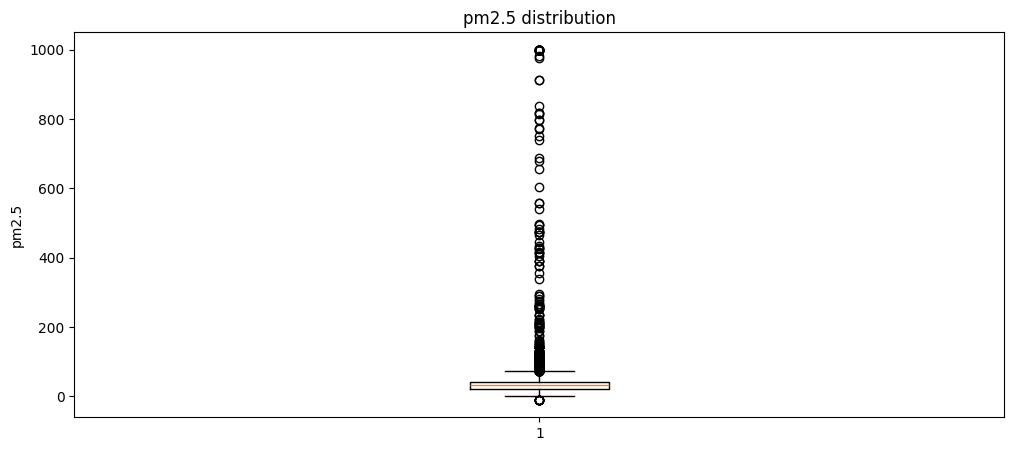

In [9]:
#check for outliers
plt.figure(figsize=(12,5))

plt.boxplot(df["pm25"])

plt.title("pm2.5 distribution")
plt.ylabel("pm2.5")
plt.show()

In [10]:
Q1 = df["pm25"].quantile(0.25)
Q3 = df["pm25"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

outliers = df[(df["pm25"] < lower) | (df["pm25"] > upper)]

print("Number of outliers:", len(outliers))
print(outliers)

Lower limit: -8.199999999999992
Upper limit: 71.79999999999998
Number of outliers: 458
                timestamp    pm25  temperature  humidity  wind_speed  \
1     2019-01-03 14:00:00    84.5         20.4        39        10.8   
2     2019-01-03 15:00:00    93.3         19.5        47        11.5   
3     2019-01-03 16:00:00    79.0         18.6        55        12.6   
12    2019-02-13 08:00:00    73.7         28.9        30        18.4   
16    2019-02-13 12:00:00    99.0         27.2        35        16.0   
...                   ...     ...          ...       ...         ...   
11669 2021-12-24 21:00:00   234.0         13.9        92         7.0   
11671 2021-12-25 07:00:00  1000.0         26.7        32         7.1   
11672 2021-12-25 12:00:00  1000.0         24.3        41         7.2   
11673 2021-12-25 22:00:00   357.0         15.1        95         9.4   
11674 2021-12-25 23:00:00   252.0         14.8        96         8.0   

       wind_direction  precipitation  
1        

In [11]:
numerical_cols = df.select_dtypes(include=np.number).columns

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\n{col}")
    print("Lower:", lower)
    print("Upper:", upper)
    print("Outliers:", len(outliers))


pm25
Lower: -8.199999999999992
Upper: 71.79999999999998
Outliers: 458

temperature
Lower: 11.95
Upper: 33.95
Outliers: 141

humidity
Lower: 8.0
Upper: 144.0
Outliers: 0

wind_speed
Lower: -1.299999999999999
Upper: 25.099999999999998
Outliers: 142

wind_direction
Lower: -156.0
Upper: 500.0
Outliers: 0

precipitation
Lower: 0.0
Upper: 0.0
Outliers: 2980


In [12]:
# PM2.5

print(df.isnull().sum())

timestamp         0
pm25              0
temperature       0
humidity          0
wind_speed        0
wind_direction    0
precipitation     0
dtype: int64


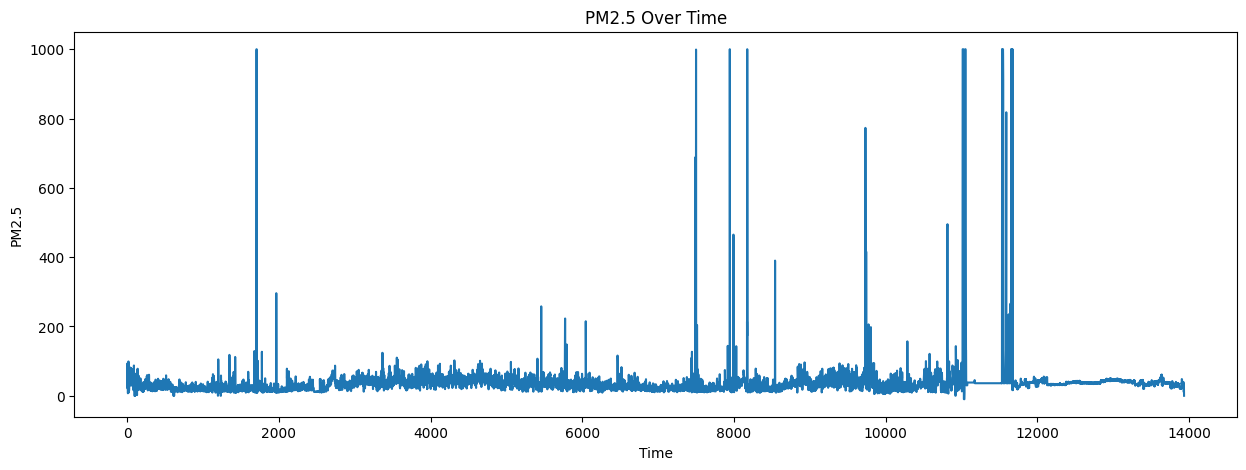

In [13]:
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["pm25"])

plt.title("PM2.5 Over Time")
plt.xlabel("Time")
plt.ylabel("PM2.5")

plt.show()

In [14]:
df.loc[df["pm25"] < 0, "pm25"] = np.nan
print(df["pm25"].isnull().sum())

df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values("timestamp")

df["pm25"] = df["pm25"].interpolate(method="linear")

print("Missing PM2.5:", df["pm25"].isnull().sum())
print("Negative PM2.5:", (df["pm25"] < 0).sum())

9
Missing PM2.5: 0
Negative PM2.5: 0


In [15]:
correlation = df.corr(numeric_only=True)

print(correlation)
#closer to 0 means very less relationships\

                    pm25  temperature  humidity  wind_speed  wind_direction  \
pm25            1.000000    -0.054175  0.001912   -0.099268       -0.090447   
temperature    -0.054175     1.000000 -0.850328    0.025397        0.055670   
humidity        0.001912    -0.850328  1.000000   -0.058710        0.212475   
wind_speed     -0.099268     0.025397 -0.058710    1.000000        0.032844   
wind_direction -0.090447     0.055670  0.212475    0.032844        1.000000   
precipitation  -0.005925    -0.028047  0.121736   -0.004604        0.113280   

                precipitation  
pm25                -0.005925  
temperature         -0.028047  
humidity             0.121736  
wind_speed          -0.004604  
wind_direction       0.113280  
precipitation        1.000000  


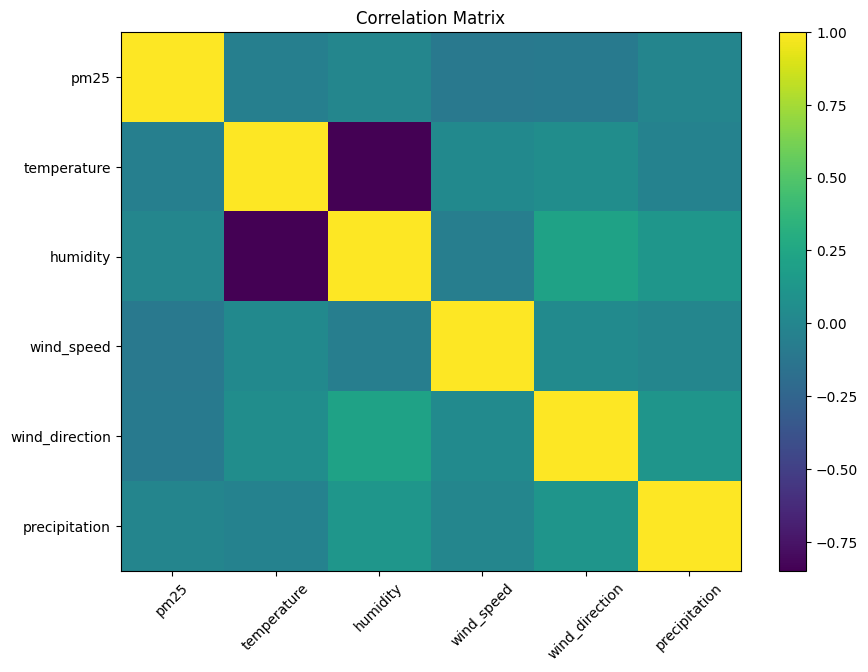

In [16]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.show()

In [17]:
df["pm25"].corr(df["pm25"].shift(1))

0.8595651037250189

In [18]:
df["pm25"].corr(df["pm25"].shift(24))

0.1580799885391115

In [19]:
# lets calculate the timely relationships i.e lag relations between pm2.5

for lag in [1, 2, 3, 6, 12, 24, 48, 72]:
    correlation = df["pm25"].corr(df["pm25"].shift(lag))
    print(f"Lag {lag}: {correlation:.3f}")

Lag 1: 0.860
Lag 2: 0.725
Lag 3: 0.615
Lag 6: 0.480
Lag 12: 0.225
Lag 24: 0.158
Lag 48: 0.067
Lag 72: 0.073


In [20]:
expected = pd.date_range(
    start=df["timestamp"].min(),
    end=df["timestamp"].max(),
    freq="h"
)

missing_hours = expected.difference(df["timestamp"])

print("Number of missing hours:", len(missing_hours))

print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())
print("Number of rows:", len(df))
print("Missing hours:", len(missing_hours))

total_expected = len(expected)

print("Expected hours:", total_expected)
print("Actual rows:", len(df))
print("Missing hours:", len(missing_hours))

Number of missing hours: 16446
First timestamp: 2019-01-03 13:00:00
Last timestamp: 2022-06-22 08:00:00
Number of rows: 13934
Missing hours: 16446
Expected hours: 30380
Actual rows: 13934
Missing hours: 16446


In [21]:
print(df["timestamp"].diff().value_counts().head(20))
#there are 778 records havind differnce of 2 hrs from the previous record
#so the data is not contiguous time series data it has few gaps

timestamp
0 days 01:00:00    12364
0 days 02:00:00      778
0 days 03:00:00      267
0 days 04:00:00      129
0 days 05:00:00       75
0 days 06:00:00       50
1 days 01:00:00       37
0 days 07:00:00       25
0 days 09:00:00       22
0 days 08:00:00       19
0 days 10:00:00       15
0 days 13:00:00       13
0 days 11:00:00        8
0 days 15:00:00        8
0 days 14:00:00        8
0 days 12:00:00        8
1 days 02:00:00        6
0 days 18:00:00        6
0 days 20:00:00        6
0 days 16:00:00        6
Name: count, dtype: int64


In [22]:
gap_mask = df["timestamp"].diff() > pd.Timedelta(hours=24)

print(df.loc[gap_mask, ["timestamp"]])

                timestamp
4     2019-02-13 00:00:00
34    2019-04-27 08:00:00
92    2019-04-30 18:00:00
147   2019-07-11 11:00:00
160   2019-07-13 00:00:00
...                   ...
12809 2022-04-28 00:00:00
12848 2022-04-30 18:00:00
12898 2022-05-04 06:00:00
13407 2022-05-28 00:00:00
13470 2022-05-31 18:00:00

[112 rows x 1 columns]


In [23]:
gap_info = pd.DataFrame({
    "previous": df["timestamp"].shift(1),
    "current": df["timestamp"],
    "gap": df["timestamp"].diff()
})

large_gaps = gap_info[gap_info["gap"] > pd.Timedelta(hours=24)]

print(large_gaps)

                 previous             current              gap
4     2019-01-03 16:00:00 2019-02-13 00:00:00 40 days 08:00:00
34    2019-02-14 05:00:00 2019-04-27 08:00:00 72 days 03:00:00
92    2019-04-29 17:00:00 2019-04-30 18:00:00  1 days 01:00:00
147   2019-05-03 01:00:00 2019-07-11 11:00:00 69 days 10:00:00
160   2019-07-11 23:00:00 2019-07-13 00:00:00  1 days 01:00:00
...                   ...                 ...              ...
12809 2022-04-26 23:00:00 2022-04-28 00:00:00  1 days 01:00:00
12848 2022-04-29 17:00:00 2022-04-30 18:00:00  1 days 01:00:00
12898 2022-05-02 21:00:00 2022-05-04 06:00:00  1 days 09:00:00
13407 2022-05-26 23:00:00 2022-05-28 00:00:00  1 days 01:00:00
13470 2022-05-30 16:00:00 2022-05-31 18:00:00  1 days 02:00:00

[112 rows x 3 columns]


In [24]:
# 1. How many large gaps?
print("Large gaps:", len(large_gaps))

# 2. Statistics of large gaps
print(large_gaps["gap"].describe())

# 3. 20 largest gaps
print(large_gaps.sort_values("gap", ascending=False).head(20))

Large gaps: 112
count                           112
mean      4 days 16:23:34.285714285
std      11 days 04:00:12.628857587
min                 1 days 01:00:00
25%                 1 days 01:00:00
50%                 1 days 09:30:00
75%                 3 days 09:00:00
max                72 days 03:00:00
Name: gap, dtype: object
                 previous             current              gap
34    2019-02-14 05:00:00 2019-04-27 08:00:00 72 days 03:00:00
147   2019-05-03 01:00:00 2019-07-11 11:00:00 69 days 10:00:00
12126 2022-02-06 12:00:00 2022-03-24 20:00:00 46 days 08:00:00
4     2019-01-03 16:00:00 2019-02-13 00:00:00 40 days 08:00:00
9876  2021-07-22 13:00:00 2021-08-25 16:00:00 34 days 03:00:00
10384 2021-09-28 23:00:00 2021-10-13 14:00:00 14 days 15:00:00
2168  2019-10-30 06:00:00 2019-11-11 10:00:00 12 days 04:00:00
9869  2021-06-23 07:00:00 2021-07-05 03:00:00 11 days 20:00:00
9851  2021-05-25 03:00:00 2021-06-05 17:00:00 11 days 14:00:00
9375  2021-01-26 21:00:00 2021-02-05 15:0

In [27]:
df["time_diff"] = df["timestamp"].diff()

df["segment"] = (
    df["time_diff"] > pd.Timedelta(hours=1)
).cumsum()

print(df["timestamp"].dt.year.value_counts().sort_index())

print(df.groupby(df["timestamp"].dt.year)["timestamp"].agg(["min", "max", "count"]))

timestamp
2019    3277
2020    5676
2021    2727
2022    2254
Name: count, dtype: int64
                          min                 max  count
timestamp                                               
2019      2019-01-03 13:00:00 2019-12-31 23:00:00   3277
2020      2020-01-01 00:00:00 2020-12-30 13:00:00   5676
2021      2021-01-01 02:00:00 2021-12-31 23:00:00   2727
2022      2022-01-01 07:00:00 2022-06-22 08:00:00   2254


In [29]:
df["time_diff"] = df["timestamp"].diff()

# Mark where continuity is broken
df["new_segment"] = (
    df["time_diff"] != pd.Timedelta(hours=1)
)#check if the differnce between this row and previous row something other than 1 hr. if other than 1 then true

# Give each continuous section a number
df["segment"] = df["new_segment"].cumsum()
#counts everytime a true appears

# Size of each continuous segment
segment_sizes = df.groupby("segment").size()

print(segment_sizes.describe())

count    1570.000000
mean        8.875159
std        28.337216
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       377.000000
dtype: float64


In [30]:
print("Segments with >= 24 hours:",
      (segment_sizes >= 24).sum())

Segments with >= 24 hours: 102


In [31]:
print("Segments with >= 48 hours:",
      (segment_sizes >= 48).sum())

Segments with >= 48 hours: 61
